In [25]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

pd.set_option("display.max_colwidth", 120)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [26]:
df=pd.read_csv("Tweets.csv")
print(df.shape)

(14640, 15)


In [27]:
print(df.head())

             tweet_id airline_sentiment  airline_sentiment_confidence  \
0  570306133677760513           neutral                        1.0000   
1  570301130888122368          positive                        0.3486   
2  570301083672813571           neutral                        0.6837   
3  570301031407624196          negative                        1.0000   
4  570300817074462722          negative                        1.0000   

  negativereason  negativereason_confidence         airline  \
0            NaN                        NaN  Virgin America   
1            NaN                     0.0000  Virgin America   
2            NaN                        NaN  Virgin America   
3     Bad Flight                     0.7033  Virgin America   
4     Can't Tell                     1.0000  Virgin America   

  airline_sentiment_gold        name negativereason_gold  retweet_count  \
0                    NaN     cairdin                 NaN              0   
1                    NaN    jnar

In [28]:
print(df.tail())

                 tweet_id airline_sentiment  airline_sentiment_confidence  \
14635  569587686496825344          positive                        0.3487   
14636  569587371693355008          negative                        1.0000   
14637  569587242672398336           neutral                        1.0000   
14638  569587188687634433          negative                        1.0000   
14639  569587140490866689           neutral                        0.6771   

               negativereason  negativereason_confidence   airline  \
14635                     NaN                     0.0000  American   
14636  Customer Service Issue                     1.0000  American   
14637                     NaN                        NaN  American   
14638  Customer Service Issue                     0.6659  American   
14639                     NaN                     0.0000  American   

      airline_sentiment_gold             name negativereason_gold  \
14635                    NaN  KristenReenders  

In [29]:
print(df.describe())

           tweet_id  airline_sentiment_confidence  negativereason_confidence  \
count  1.464000e+04                  14640.000000               10522.000000   
mean   5.692184e+17                      0.900169                   0.638298   
std    7.791112e+14                      0.162830                   0.330440   
min    5.675883e+17                      0.335000                   0.000000   
25%    5.685592e+17                      0.692300                   0.360600   
50%    5.694779e+17                      1.000000                   0.670600   
75%    5.698905e+17                      1.000000                   1.000000   
max    5.703106e+17                      1.000000                   1.000000   

       retweet_count  
count   14640.000000  
mean        0.082650  
std         0.745778  
min         0.000000  
25%         0.000000  
50%         0.000000  
75%         0.000000  
max        44.000000  


In [30]:
print("\nMissing values (share of rows):")
print(df.isna().mean().round(3).sort_values(ascending=False))
print(("\nfully duplicated rows:", df.duplicated().sum()))
print("Duplicated tweet_ids:", df["tweet_id"].duplicated().sum())


Missing values (share of rows):
negativereason_gold             0.998
airline_sentiment_gold          0.997
tweet_coord                     0.930
negativereason                  0.373
user_timezone                   0.329
tweet_location                  0.323
negativereason_confidence       0.281
airline                         0.000
tweet_id                        0.000
airline_sentiment               0.000
airline_sentiment_confidence    0.000
text                            0.000
retweet_count                   0.000
name                            0.000
tweet_created                   0.000
dtype: float64
('\nfully duplicated rows:', np.int64(36))
Duplicated tweet_ids: 155


airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64
airline
United            3822
US Airways        2913
American          2759
Southwest         2420
Delta             2222
Virgin America     504
Name: count, dtype: int64


airline_sentiment,negative,neutral,positive
airline,,,
American,0.71,0.17,0.12
Delta,0.43,0.33,0.24
Southwest,0.49,0.27,0.24
US Airways,0.78,0.13,0.09
United,0.69,0.18,0.13
Virgin America,0.36,0.34,0.30


negativereason
Customer Service Issue         2910
Late Flight                    1665
Can't Tell                     1190
Cancelled Flight                847
Lost Luggage                    724
Bad Flight                      580
Flight Booking Problems         529
Flight Attendant Complaints     481
longlines                       178
Damaged Luggage                  74
Name: count, dtype: int64


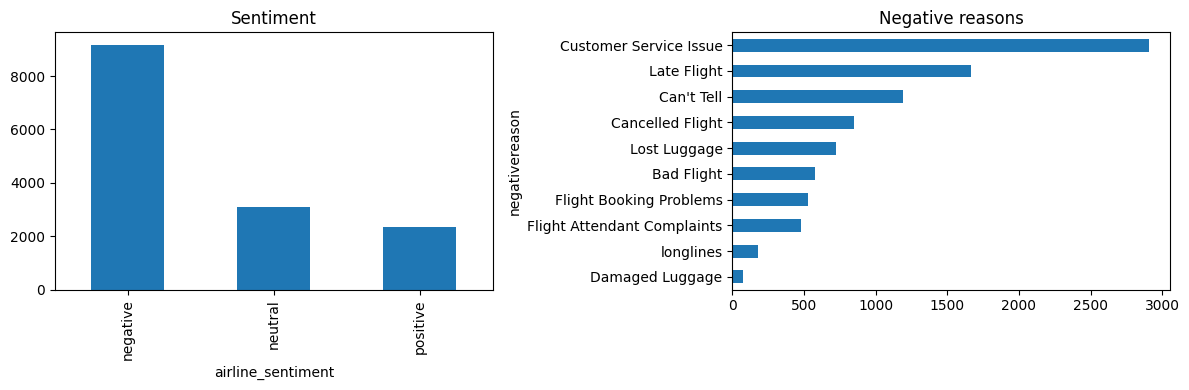

In [31]:
#labels and airlines
print(df["airline_sentiment"].value_counts())
print(df["airline"].value_counts())

#sentiment share per airline
display(pd.crosstab(df["airline"], df["airline_sentiment"], normalize="index").round(2))

#why people complain
print(df["negativereason"]. value_counts())

fig, ax = plt.subplots(1,2, figsize=(12,4))
df["airline_sentiment"].value_counts().plot.bar(ax=ax[0],title="Sentiment")
df["negativereason"].value_counts().plot.barh(ax=ax[1],title="Negative reasons").invert_yaxis()
plt.tight_layout();plt.show()

,n_chars,n_words
count,14640.000000,14640.000000
mean,103.822063,17.653415
std,36.277339,6.882259
min,12.000000,2.000000
25%,77.000000,12.000000
50%,114.000000,19.000000
75%,136.000000,23.000000
max,186.000000,36.000000


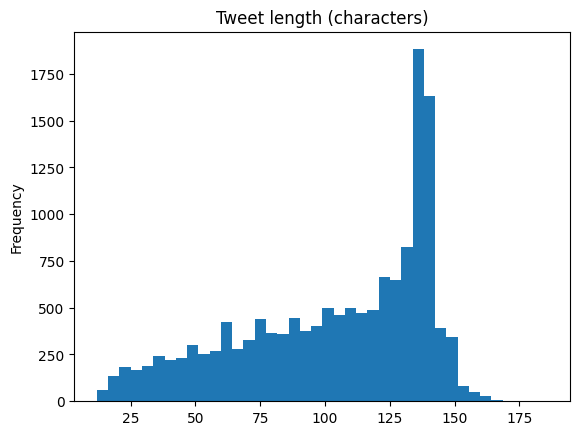

Tweets with URLS:  0.08
Tweets with @mentions: 1.0
Tweets with #hashtags: 0.17

--- POSITIVE ---
• @united This is probably the least dependable airline in the Western Hemisphere. @united does not belong in Star Alliance, but SkyTeam
• @USAirways will do. Hoping for a voucher for a future flight #Optimistic
• @SouthwestAir thanks for an awesome flight and connection! We were delayed but your staff and crew were purely amazing!
• @USAirways YOU ARE AMAZING!!! YOU ARE THE BEST!!! FOLLOW ME PLEASE 🙏🙏🙏😢😢😢🙏🙏🙏

--- NEUTRAL ---
• @united so if this game was the one reason I payed for @DIRECTV is there something we could work out here? http://t.co/HQDTK6aTue
• @AmericanAir well you spelled my name wrong.
• @AmericanAir if I've booked an AA award on USAir metal, and space opens up on AA metal, can I change to the AA flight without fees?
• @AmericanAir Can I use an SWU on an Finnair codeshare of an American operated flight (JFK-MAN)?  Thanks in advance for the help!

--- NEGATIVE ---
• @USAirway

In [32]:
#the text itself
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str. split().str.len()
display(df[["n_chars","n_words"]].describe())

df["n_chars"].plot.hist(bins=40, title="Tweet length (characters)")
plt.show()

print("Tweets with URLS: ", df["text"].str.contains("http").mean().round(3))
print("Tweets with @mentions:", df["text"].str.contains("@").mean().round(3))
print("Tweets with #hashtags:", df["text"].str.contains("#").mean().round(3))

# Read real examples per class
for s in ["positive", "neutral", "negative"]:
    print(f"\n--- {s.upper()} ---")
    for t in df[df["airline_sentiment"] == s]["text"].sample(4, random_state=1):
        print("•", t)

In [33]:
from nltk.tokenize import TweetTokenizer
from nltk.probability import FreqDist
from nltk.corpus import stopwords

tok = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True)
stop = set(stopwords.words("english"))

tokens = [w for t in df["text"] for w in tok.tokenize(t)]
words = [w for w in tokens if w.isalpha() and w not in stop]

print("Total tokens:", len(tokens), "| unique:", len(set(tokens)))
print(FreqDist(words).most_common(20))

Total tokens: 277652 | unique: 15997
[('flight', 3898), ('get', 1340), ('thanks', 1075), ('cancelled', 1056), ('service', 959), ('help', 846), ('time', 775), ('customer', 749), ('hours', 674), ('us', 674), ('hold', 641), ('flights', 640), ('plane', 625), ('thank', 603), ('still', 581), ('please', 563), ('one', 561), ('need', 556), ('would', 549), ('delayed', 535)]


In [34]:
import re, html
import pandas as pd
import nltk
from nltk.tokenize import TweetTokenizer
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer
from nltk.corpus import stopwords, wordnet

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

df = pd.read_csv("Tweets.csv")[["tweet_id", "airline", "airline_sentiment", "text"]]

In [35]:
# Remove repeated tweets
df = df.drop_duplicates(subset="tweet_id").reset_index(drop=True)

URL_RE     = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#(\w+)")

def clean_text(text):
    text = html.unescape(text)          # &amp; -> &
    text = URL_RE.sub(" ", text)        # drop links
    text = MENTION_RE.sub(" ", text)    # drop @airline handles
    text = HASHTAG_RE.sub(r"\1", text)  # #oscars -> oscars
    text = text.lower()
    return re.sub(r"\s+", " ", text).strip()

df["clean_text"] = df["text"].map(clean_text)
df[["text", "clean_text"]].head()

,text,clean_text
0,@VirginAmerica What @dhepburn said.,what said.
1,@VirginAmerica plus you've added commercials to the experience... tacky.,plus you've added commercials to the experience... tacky.
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,i didn't today... must mean i need to take another trip!
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have littl...","it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces & they have little recourse"
4,@VirginAmerica and it's a really big bad thing about it,and it's a really big bad thing about it


In [36]:
#tokenization
tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True)

# keep only word tokens (drops punctuation, numbers, emoticons)
WORD_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")

df["tokens"] = df["clean_text"].map(
    lambda t: [w for w in tokenizer.tokenize(t) if WORD_RE.fullmatch(w)]
)
df[["clean_text", "tokens"]].head()

,clean_text,tokens
0,what said.,"[what, said]"
1,plus you've added commercials to the experience... tacky.,"[plus, you've, added, commercials, to, the, experience, tacky]"
2,i didn't today... must mean i need to take another trip!,"[i, didn't, today, must, mean, i, need, to, take, another, trip]"
3,"it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces & they have little recourse","[it's, really, aggressive, to, blast, obnoxious, entertainment, in, your, guests, faces, they, have, little, recourse]"
4,and it's a really big bad thing about it,"[and, it's, a, really, big, bad, thing, about, it]"


In [37]:
# stopword removal (keep negations: "not", "no", "can't", "didn't" change sentiment)
stop = set(stopwords.words("english"))
negations = {w for w in stop if w in {"no", "nor", "not"} or "n't" in w}
stop -= negations

df["tokens_nostop"] = df["tokens"].map(lambda ts: [w for w in ts if w not in stop])

# drop tweets with no tokens left
df = df[df["tokens_nostop"].str.len() > 0].reset_index(drop=True)


In [38]:
#lemmatization (POS-aware)
lemmatizer = WordNetLemmatizer()

def to_wordnet_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB,
            "N": wordnet.NOUN, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

def lemmatize(tokens):
    return [lemmatizer.lemmatize(w, to_wordnet_pos(t))
            for w, t in nltk.pos_tag(tokens) if w not in stop]

df["lemmas"] = df["tokens"].map(lemmatize)

In [39]:
# Initialize stemmers
porter = PorterStemmer()
snowball = SnowballStemmer("english")

# Create the missing columns
df["stems_porter"] = df["tokens_nostop"].map(lambda ts: [porter.stem(w) for w in ts])
df["stems_snowball"] = df["tokens_nostop"].map(lambda ts: [snowball.stem(w) for w in ts])

cols = ["tokens_nostop", "stems_porter", "stems_snowball", "lemmas"]

print("Vocabulary size:")
for c in cols:
    print(f"  {c:15s}", len({w for ts in df[c] for w in ts}))

for i in range(3):
    r = df.loc[i]
    print("\nORIGINAL :", r["text"])
    for c in cols:
        print(f"{c:15s}:", r[c])

# Words where the stem and lemma differ
examples = {}
for toks, st, lm in zip(df["tokens_nostop"], df["stems_porter"], df["lemmas"]):
    for t, s, l in zip(toks, st, lm):
        if s != l and t not in examples:
            examples[t] = (s, l)
pd.DataFrame(examples, index=["porter_stem", "lemma"]).T.head(15)

Vocabulary size:
  tokens_nostop   10972
  stems_porter    8345
  stems_snowball  8225
  lemmas          9344

ORIGINAL : @VirginAmerica What @dhepburn said.
tokens_nostop  : ['said']
stems_porter   : ['said']
stems_snowball : ['said']
lemmas         : ['say']

ORIGINAL : @VirginAmerica plus you've added commercials to the experience... tacky.
tokens_nostop  : ['plus', 'added', 'commercials', 'experience', 'tacky']
stems_porter   : ['plu', 'ad', 'commerci', 'experi', 'tacki']
stems_snowball : ['plus', 'ad', 'commerci', 'experi', 'tacki']
lemmas         : ['plus', 'added', 'commercial', 'experience', 'tacky']

ORIGINAL : @VirginAmerica I didn't today... Must mean I need to take another trip!
tokens_nostop  : ["didn't", 'today', 'must', 'mean', 'need', 'take', 'another', 'trip']
stems_porter   : ["didn't", 'today', 'must', 'mean', 'need', 'take', 'anoth', 'trip']
stems_snowball : ["didn't", 'today', 'must', 'mean', 'need', 'take', 'anoth', 'trip']
lemmas         : ["didn't", 'today', 'mu

,porter_stem,lemma
said,said,say
plus,plu,plus
added,ad,added
commercials,commerci,commercial
experience,experi,experience
tacky,tacki,tacky
another,anoth,another
really,realli,really
aggressive,aggress,aggressive
obnoxious,obnoxi,obnoxious


In [40]:
out = df.copy()
for c in ["tokens", "tokens_nostop", "stems_porter", "stems_snowball", "lemmas"]:
    out[c] = out[c].map(" ".join)

out.to_csv("tweets_preprocessed.csv", index=False)

from google.colab import files
files.download("tweets_preprocessed.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>